# Phase Shift Analysis - FRaw vs FF_EE

This notebook analyzes the phase difference between FRaw and FF_EE:
- FF_EE is FRaw filtered through a 5Hz low-pass filter
- Expected phase shift: ~32ms at 250Hz sampling rate
- Tests different phase shifts to find optimal alignment
- Reports RMS error for different phase shifts


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal
import warnings
warnings.filterwarnings('ignore')

# Set up paths
data_path = Path('../data/Aug29/2_DyF_L2.jsonl')
print(f"Loading data from: {data_path}")


Loading data from: ..\data\Aug29\2_DyF_L2.jsonl


In [2]:
# Load the JSONL file
data_points = []
with open(data_path, 'r') as f:
    for line in f:
        if line.strip():  # Skip empty lines
            data_points.append(json.loads(line))

print(f"Loaded {len(data_points)} data points")
print(f"First timestamp: {data_points[0]['timestamp']}")
print(f"Last timestamp: {data_points[-1]['timestamp']}")

# Extract timestamps and sampling info
timestamps = np.array([dp['timestamp'] for dp in data_points])
actual_intervals = np.diff(timestamps)
mean_freq = 1.0 / np.mean(actual_intervals)
print(f"Mean sampling frequency: {mean_freq:.2f} Hz")


Loaded 48745 data points
First timestamp: 1756487196.7640388
Last timestamp: 1756487391.7392745
Mean sampling frequency: 250.00 Hz


In [3]:
# Extract FRaw and FF_EE for all 6 dimensions
FRaw = np.array([dp['FRaw'] for dp in data_points])  # Shape: (N, 6)
FF_EE = np.array([dp['FF_EE'] for dp in data_points])  # Shape: (N, 6)

print(f"FRaw shape: {FRaw.shape}")
print(f"FF_EE shape: {FF_EE.shape}")

# Calculate expected phase shift (32ms at 250Hz)
expected_phase_shift_ms = 32
expected_phase_shift_samples = int(expected_phase_shift_ms / 1000 * mean_freq)
print(f"\nExpected phase shift: {expected_phase_shift_ms} ms")
print(f"Expected phase shift in samples (at {mean_freq:.1f}Hz): {expected_phase_shift_samples} samples")


FRaw shape: (48745, 6)
FF_EE shape: (48745, 6)

Expected phase shift: 32 ms
Expected phase shift in samples (at 250.0Hz): 8 samples


In [4]:
# Function to calculate RMS error between two signals
def calculate_rms_error(signal1, signal2):
    """Calculate RMS error between two signals"""
    if len(signal1) != len(signal2):
        min_len = min(len(signal1), len(signal2))
        signal1 = signal1[:min_len]
        signal2 = signal2[:min_len]
    return np.sqrt(np.mean((signal1 - signal2)**2))

# Function to shift signal by n samples (positive shift delays the signal)
def shift_signal(sig, n_samples):
    """Shift signal by n_samples. Positive n_samples delays the signal."""
    if n_samples == 0:
        return sig.copy()
    elif n_samples > 0:
        # Delay: pad zeros at the beginning, crop at the end
        shifted = np.zeros_like(sig)
        shifted[n_samples:] = sig[:-n_samples]
        return shifted
    else:
        # Advance: crop at the beginning, pad zeros at the end
        n_samples = abs(n_samples)
        shifted = np.zeros_like(sig)
        shifted[:-n_samples] = sig[n_samples:]
        return shifted


In [5]:
# Test different phase shifts
# Test range: -50ms to +150ms (to cover the expected 32ms and beyond)
min_shift_ms = -50
max_shift_ms = 150
step_ms = 1

phase_shifts_ms = np.arange(min_shift_ms, max_shift_ms + step_ms, step_ms)
phase_shifts_samples = (phase_shifts_ms / 1000 * mean_freq).astype(int)

print(f"Testing phase shifts from {min_shift_ms}ms to {max_shift_ms}ms in {step_ms}ms steps")
print(f"Total phase shifts to test: {len(phase_shifts_ms)}")

# Calculate RMS errors for each dimension and each phase shift
rms_errors = np.zeros((len(phase_shifts_ms), 6))  # 6 dimensions

for i, shift_samples in enumerate(phase_shifts_samples):
    # Shift FF_EE by shift_samples (positive shift delays FF_EE)
    FF_EE_shifted = shift_signal(FF_EE, shift_samples)
    
    # Calculate RMS error for each dimension
    for dim in range(6):
        rms_errors[i, dim] = calculate_rms_error(FRaw[:, dim], FF_EE_shifted[:, dim])

# Calculate overall RMS (average across all dimensions)
overall_rms = np.mean(rms_errors, axis=1)

print("\nRMS error calculation complete")


Testing phase shifts from -50ms to 150ms in 1ms steps
Total phase shifts to test: 201

RMS error calculation complete


In [6]:
# Find optimal phase shift (minimum RMS error)
optimal_idx = np.argmin(overall_rms)
optimal_shift_ms = phase_shifts_ms[optimal_idx]
optimal_shift_samples = phase_shifts_samples[optimal_idx]
optimal_rms = overall_rms[optimal_idx]

print("=== Phase Shift Analysis Results ===")
print(f"Optimal phase shift: {optimal_shift_ms:.1f} ms ({optimal_shift_samples} samples)")
print(f"Minimum RMS error: {optimal_rms:.6f}")
print(f"\nExpected phase shift: {expected_phase_shift_ms} ms ({expected_phase_shift_samples} samples)")
print(f"Difference from expected: {abs(optimal_shift_ms - expected_phase_shift_ms):.1f} ms")

# Also check RMS at expected phase shift
expected_idx = np.argmin(np.abs(phase_shifts_ms - expected_phase_shift_ms))
expected_rms = overall_rms[expected_idx]
print(f"RMS at expected phase shift ({expected_phase_shift_ms}ms): {expected_rms:.6f}")

# Per-dimension results
print(f"\n=== Per-Dimension Results ===")
dim_names = ['Fx', 'Fy', 'Fz', 'Mx', 'My', 'Mz']
for dim in range(6):
    dim_optimal_idx = np.argmin(rms_errors[:, dim])
    dim_optimal_shift_ms = phase_shifts_ms[dim_optimal_idx]
    dim_optimal_rms = rms_errors[dim_optimal_idx, dim]
    print(f"{dim_names[dim]}: Optimal shift = {dim_optimal_shift_ms:.1f}ms, RMS = {dim_optimal_rms:.6f}")


=== Phase Shift Analysis Results ===
Optimal phase shift: -11.0 ms (-2 samples)
Minimum RMS error: 0.144036

Expected phase shift: 32 ms (8 samples)
Difference from expected: 43.0 ms
RMS at expected phase shift (32ms): 0.154617

=== Per-Dimension Results ===
Fx: Optimal shift = -11.0ms, RMS = 0.248892
Fy: Optimal shift = -15.0ms, RMS = 0.298054
Fz: Optimal shift = -3.0ms, RMS = 0.253094
Mx: Optimal shift = -11.0ms, RMS = 0.025141
My: Optimal shift = -11.0ms, RMS = 0.020989
Mz: Optimal shift = -15.0ms, RMS = 0.011061


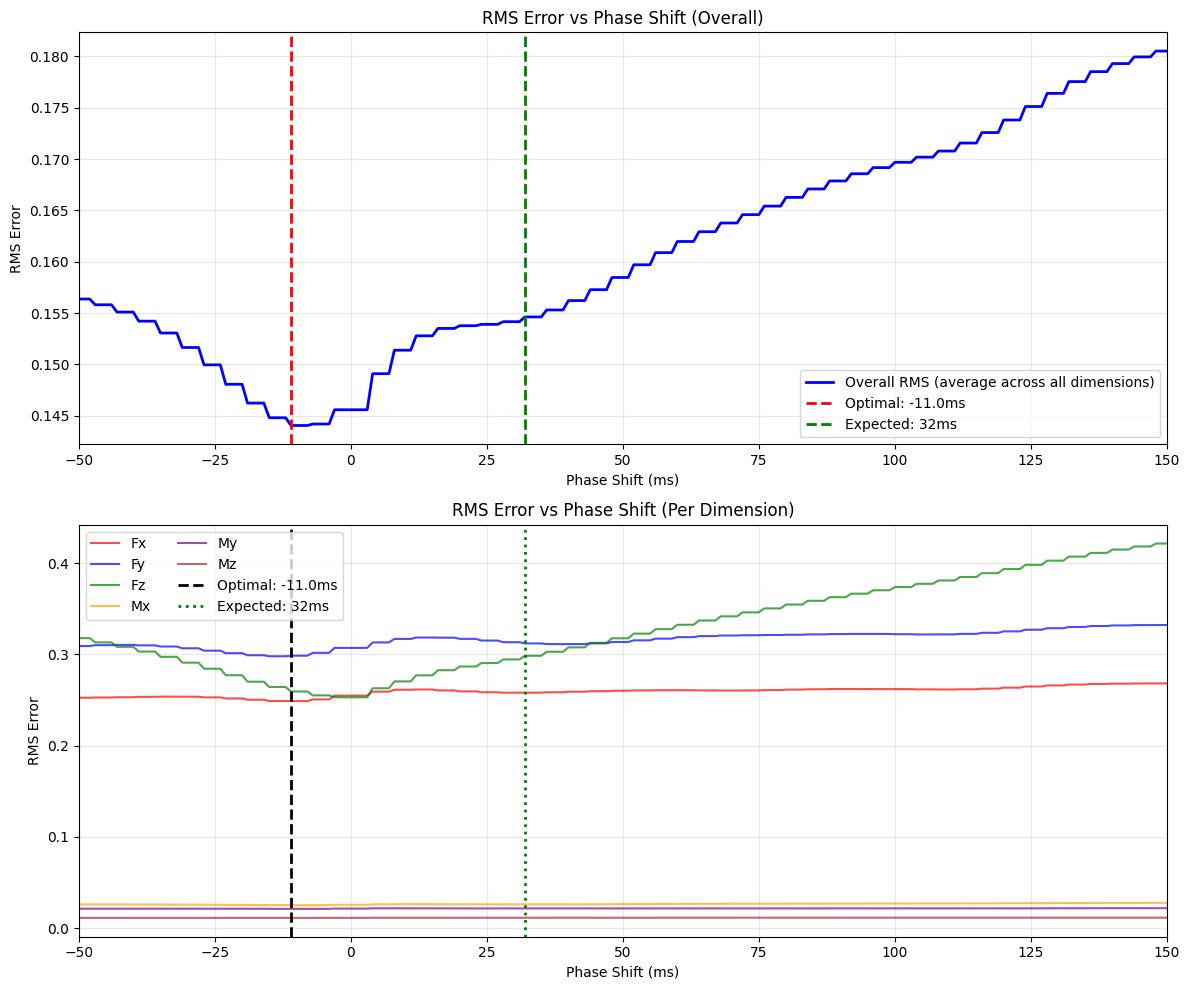

In [7]:
# Plot RMS error vs phase shift
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Overall RMS
ax1 = axes[0]
ax1.plot(phase_shifts_ms, overall_rms, 'b-', linewidth=2, label='Overall RMS (average across all dimensions)')
ax1.axvline(x=optimal_shift_ms, color='r', linestyle='--', linewidth=2, label=f'Optimal: {optimal_shift_ms:.1f}ms')
ax1.axvline(x=expected_phase_shift_ms, color='g', linestyle='--', linewidth=2, label=f'Expected: {expected_phase_shift_ms}ms')
ax1.set_xlabel('Phase Shift (ms)')
ax1.set_ylabel('RMS Error')
ax1.set_title('RMS Error vs Phase Shift (Overall)')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xlim(min_shift_ms, max_shift_ms)

# Per-dimension RMS
ax2 = axes[1]
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']
for dim in range(6):
    ax2.plot(phase_shifts_ms, rms_errors[:, dim], color=colors[dim], linewidth=1.5, 
             label=f'{dim_names[dim]}', alpha=0.7)
ax2.axvline(x=optimal_shift_ms, color='k', linestyle='--', linewidth=2, label=f'Optimal: {optimal_shift_ms:.1f}ms')
ax2.axvline(x=expected_phase_shift_ms, color='g', linestyle=':', linewidth=2, label=f'Expected: {expected_phase_shift_ms}ms')
ax2.set_xlabel('Phase Shift (ms)')
ax2.set_ylabel('RMS Error')
ax2.set_title('RMS Error vs Phase Shift (Per Dimension)')
ax2.legend(ncol=2)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(min_shift_ms, max_shift_ms)

plt.tight_layout()
plt.show()


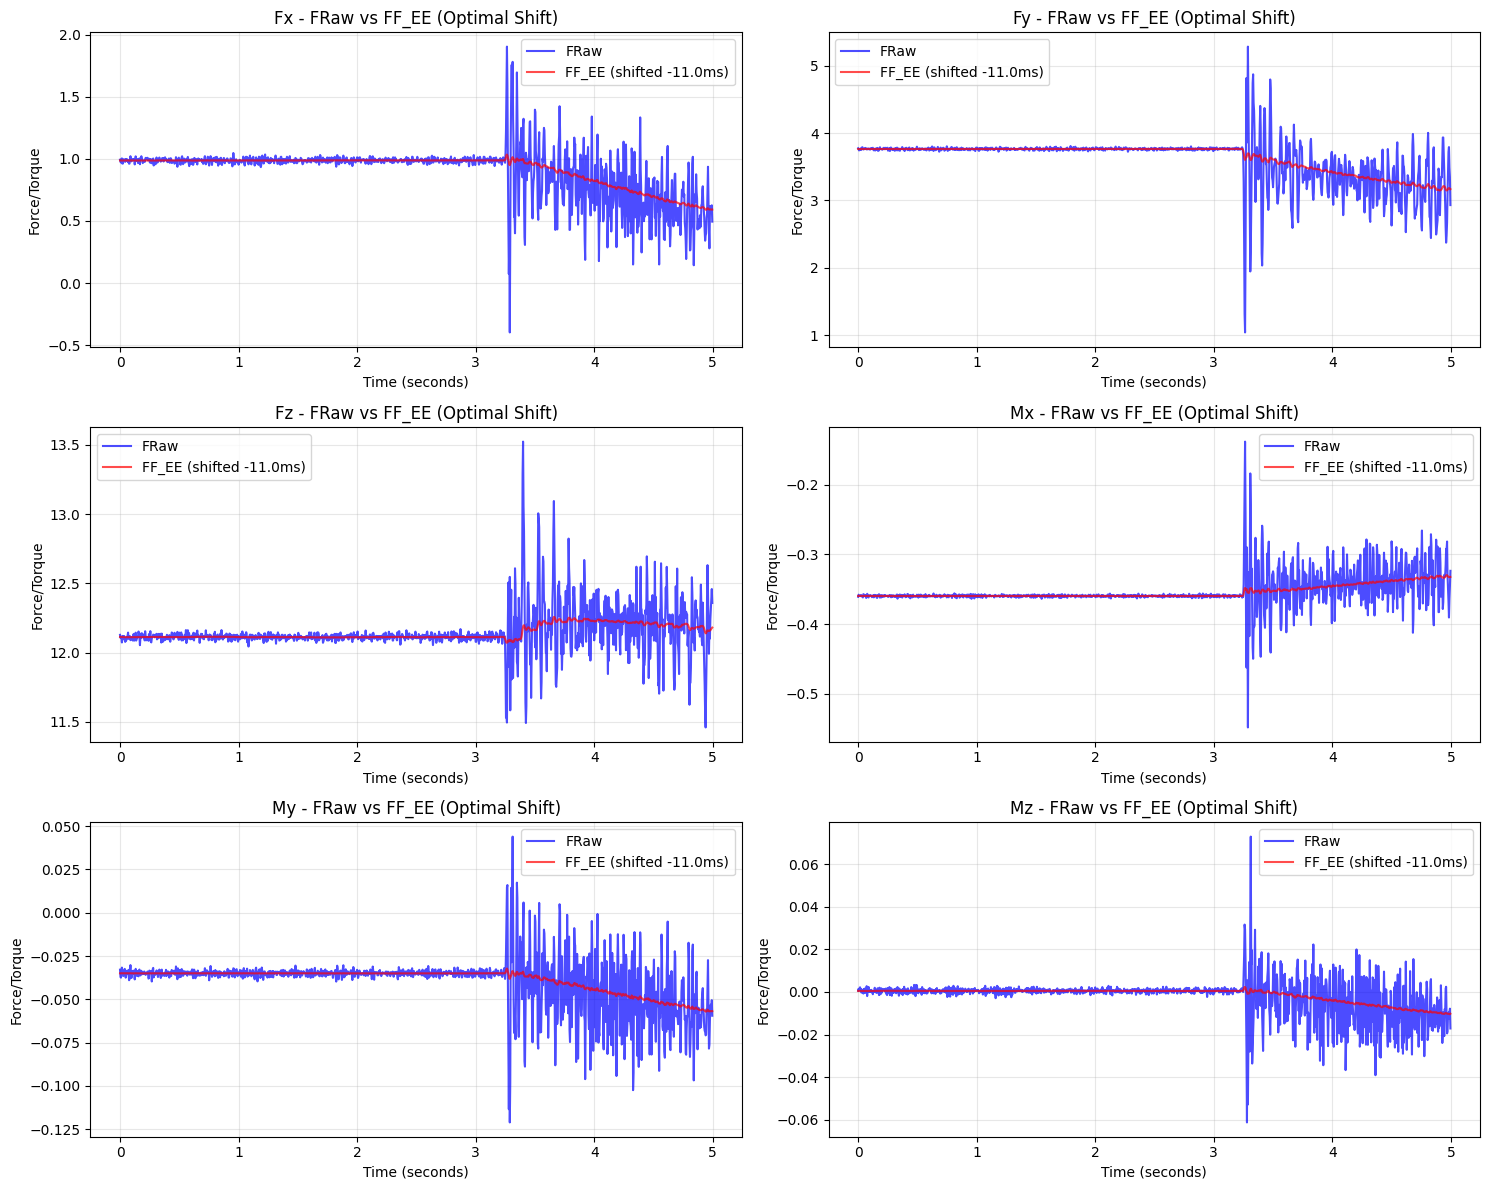

In [8]:
# Plot FRaw and FF_EE with optimal phase shift
# Shift FF_EE by optimal shift
FF_EE_shifted_optimal = shift_signal(FF_EE, optimal_shift_samples)

# Select a time window for detailed visualization (e.g., first 5 seconds)
time_window_seconds = 5
time_window_samples = int(time_window_seconds * mean_freq)
time_window_samples = min(time_window_samples, len(FRaw))

# Create time axis in seconds
time_axis = np.arange(time_window_samples) / mean_freq

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Plot both signals
    ax.plot(time_axis, FRaw[:time_window_samples, dim], 'b-', linewidth=1.5, 
            label='FRaw', alpha=0.7)
    ax.plot(time_axis, FF_EE_shifted_optimal[:time_window_samples, dim], 'r-', linewidth=1.5, 
            label=f'FF_EE (shifted {optimal_shift_ms:.1f}ms)', alpha=0.7)
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Force/Torque')
    ax.set_title(f'{dim_names[dim]} - FRaw vs FF_EE (Optimal Shift)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


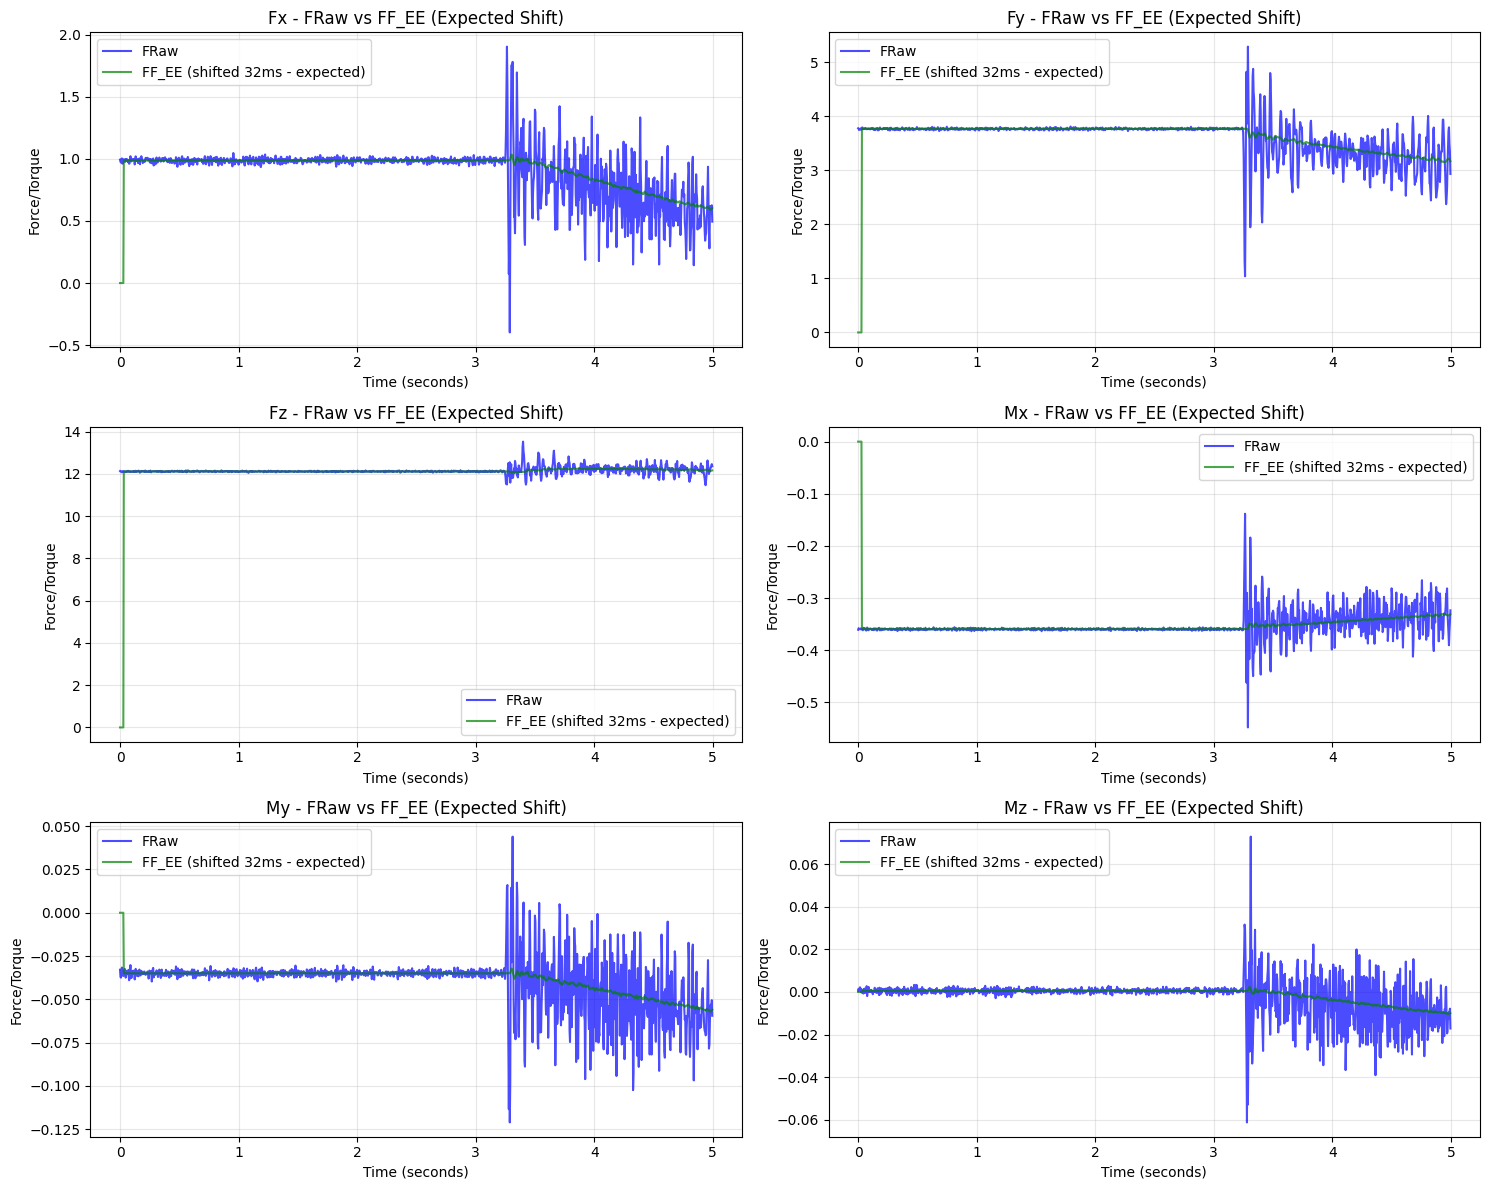

In [9]:
# Also plot with expected phase shift for comparison
FF_EE_shifted_expected = shift_signal(FF_EE, expected_phase_shift_samples)

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Plot both signals
    ax.plot(time_axis, FRaw[:time_window_samples, dim], 'b-', linewidth=1.5, 
            label='FRaw', alpha=0.7)
    ax.plot(time_axis, FF_EE_shifted_expected[:time_window_samples, dim], 'g-', linewidth=1.5, 
            label=f'FF_EE (shifted {expected_phase_shift_ms}ms - expected)', alpha=0.7)
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Force/Torque')
    ax.set_title(f'{dim_names[dim]} - FRaw vs FF_EE (Expected Shift)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


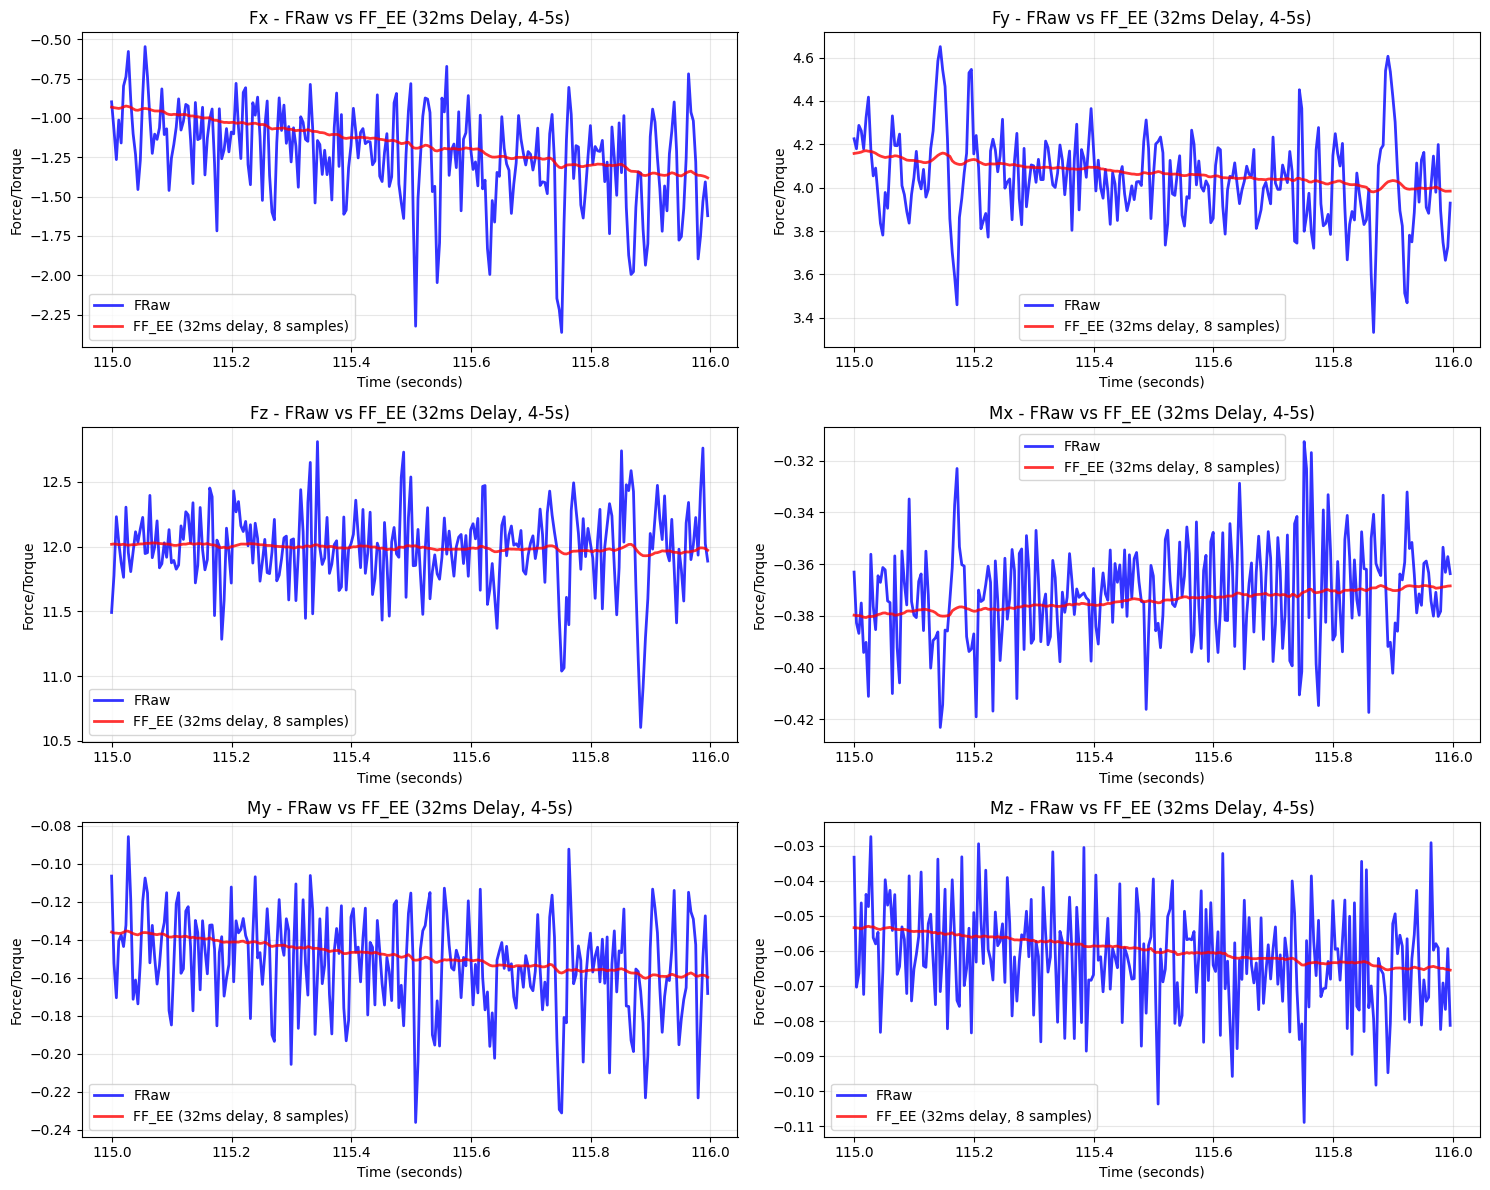


=== RMS Error with 32ms (8 samples) delay ===
Overall RMS error: 0.144036
Fx: 0.248892
Fy: 0.298690
Fz: 0.259431
Mx: 0.025141
My: 0.020989
Mz: 0.011074


In [29]:
# Plot FRaw and FF_EE with 32ms (8 samples) delay
shift_32ms_samples = -2  # 32ms at 250Hz = 8 samples
FF_EE_shifted_32ms = shift_signal(FF_EE, shift_32ms_samples)

# Select a time window from 4 to 5 seconds for detailed visualization
start_time_seconds = 115
end_time_seconds = 116
start_sample = int(start_time_seconds * mean_freq)
end_sample = int(end_time_seconds * mean_freq)
end_sample = min(end_sample, len(FRaw))

# Extract the data for the time window
FRaw_window = FRaw[start_sample:end_sample]
FF_EE_shifted_32ms_window = FF_EE_shifted_32ms[start_sample:end_sample]

# Create time axis in seconds (from 4 to 5 seconds)
time_axis = np.arange(start_sample, end_sample) / mean_freq

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Plot both signals on top of each other
    ax.plot(time_axis, FRaw_window[:, dim], 'b-', linewidth=2, 
            label='FRaw', alpha=0.8)
    ax.plot(time_axis, FF_EE_shifted_32ms_window[:, dim], 'r-', linewidth=2, 
            label=f'FF_EE (32ms delay, 8 samples)', alpha=0.8)
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Force/Torque')
    ax.set_title(f'{dim_names[dim]} - FRaw vs FF_EE (32ms Delay, 4-5s)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate RMS error with 32ms shift
rms_32ms = calculate_rms_error(FRaw, FF_EE_shifted_32ms)
rms_32ms_overall = np.mean([calculate_rms_error(FRaw[:, dim], FF_EE_shifted_32ms[:, dim]) 
                            for dim in range(6)])
print(f"\n=== RMS Error with 32ms (8 samples) delay ===")
print(f"Overall RMS error: {rms_32ms_overall:.6f}")
for dim in range(6):
    dim_rms = calculate_rms_error(FRaw[:, dim], FF_EE_shifted_32ms[:, dim])
    print(f"{dim_names[dim]}: {dim_rms:.6f}")


## Understanding Phase Shift Direction

**What does a -2 sample shift mean?**

- **-2 samples** means FF_EE is being **advanced** (shifted earlier in time)
- **Positive shift** (e.g., +8 samples) means FF_EE is being **delayed** (shifted later in time)

**Which signal happens first (original timing, before shifting)?**

With an optimal shift of **-2 samples**:
- This means FF_EE needs to be **pulled back** by 2 samples to align with FRaw
- Therefore, **originally FF_EE is happening AFTER FRaw** (FF_EE is lagging)
- FRaw happens first, then FF_EE happens ~2 samples later (at 250Hz, that's ~8ms later)
- The -2 sample shift advances FF_EE to align it with FRaw

**Summary:**
- **Original timing**: FRaw → (2 samples later) → FF_EE
- **After -2 sample shift**: FRaw and FF_EE are aligned


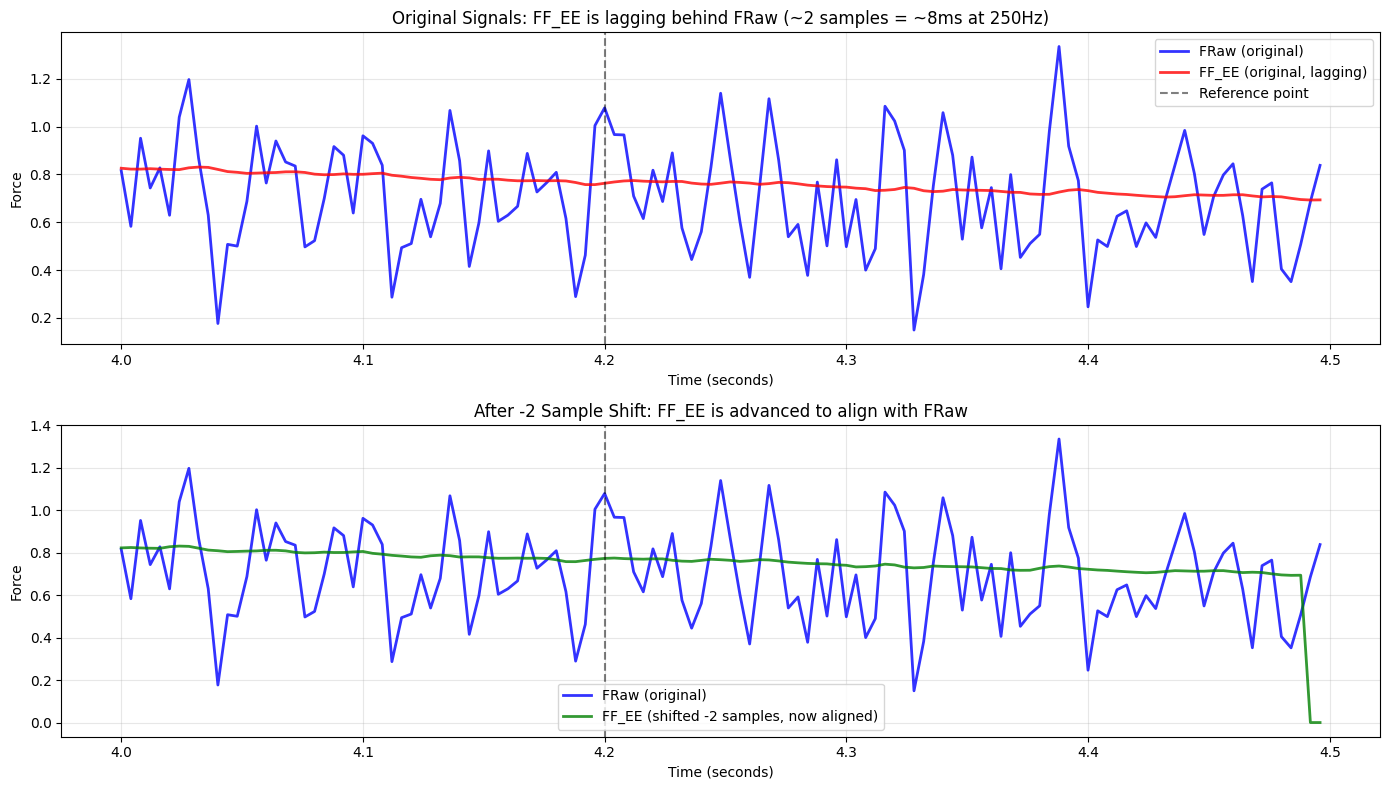


At 250Hz sampling rate:
- 2 samples = 8.00 ms
- Original: FRaw happens first, FF_EE happens ~2 samples (~8.00ms) later
- After -2 shift: FF_EE is advanced by 2 samples to align with FRaw


In [30]:
# Visualize what the -2 sample shift means
# Show a small time window to demonstrate the shift

# Select a small window for demonstration (e.g., 0.5 seconds around 4 seconds)
demo_start = 4.0
demo_end = 4.5
demo_start_sample = int(demo_start * mean_freq)
demo_end_sample = int(demo_end * mean_freq)
demo_end_sample = min(demo_end_sample, len(FRaw))

# Create time axis
demo_time = np.arange(demo_start_sample, demo_end_sample) / mean_freq

# Get the signals
FRaw_demo = FRaw[demo_start_sample:demo_end_sample, 0]  # Fx dimension
FF_EE_original = FF_EE[demo_start_sample:demo_end_sample, 0]  # Original FF_EE
FF_EE_shifted_neg2 = shift_signal(FF_EE[demo_start_sample:demo_end_sample], -2)[:, 0]  # Shifted -2 samples

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Plot 1: Original signals (showing FF_EE lagging)
ax1 = axes[0]
ax1.plot(demo_time, FRaw_demo, 'b-', linewidth=2, label='FRaw (original)', alpha=0.8)
ax1.plot(demo_time, FF_EE_original, 'r-', linewidth=2, label='FF_EE (original, lagging)', alpha=0.8)
ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Force')
ax1.set_title('Original Signals: FF_EE is lagging behind FRaw (~2 samples = ~8ms at 250Hz)')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.axvline(x=demo_time[50], color='k', linestyle='--', alpha=0.5, label='Reference point')
ax1.legend()

# Plot 2: After -2 sample shift (aligned)
ax2 = axes[1]
ax2.plot(demo_time, FRaw_demo, 'b-', linewidth=2, label='FRaw (original)', alpha=0.8)
ax2.plot(demo_time, FF_EE_shifted_neg2, 'g-', linewidth=2, label='FF_EE (shifted -2 samples, now aligned)', alpha=0.8)
ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('Force')
ax2.set_title('After -2 Sample Shift: FF_EE is advanced to align with FRaw')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.axvline(x=demo_time[50], color='k', linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"\nAt 250Hz sampling rate:")
print(f"- 2 samples = {2/mean_freq*1000:.2f} ms")
print(f"- Original: FRaw happens first, FF_EE happens ~2 samples (~{2/mean_freq*1000:.2f}ms) later")
print(f"- After -2 shift: FF_EE is advanced by 2 samples to align with FRaw")


In [10]:
# Compare RMS errors at different phase shifts
zero_shift_idx = np.argmin(np.abs(phase_shifts_ms - 0))
no_shift_rms = overall_rms[zero_shift_idx]

print("\n=== RMS Error Comparison ===")
print(f"No shift (0ms): {no_shift_rms:.6f}")
print(f"Expected shift ({expected_phase_shift_ms}ms): {expected_rms:.6f}")
print(f"Optimal shift ({optimal_shift_ms:.1f}ms): {optimal_rms:.6f}")

improvement_over_no_shift = (no_shift_rms - optimal_rms) / no_shift_rms * 100
improvement_over_expected = (expected_rms - optimal_rms) / expected_rms * 100

print(f"\nImprovement with optimal shift vs no shift: {improvement_over_no_shift:.2f}%")
print(f"Improvement with optimal shift vs expected shift: {improvement_over_expected:.2f}%")

# Create summary table
summary_data = {
    'Phase Shift (ms)': [0, expected_phase_shift_ms, optimal_shift_ms],
    'Phase Shift (samples)': [0, expected_phase_shift_samples, optimal_shift_samples],
    'RMS Error': [
        no_shift_rms,
        expected_rms,
        optimal_rms
    ]
}
summary_df = pd.DataFrame(summary_data)
summary_df.index = ['No shift', 'Expected shift', 'Optimal shift']
print("\n=== Summary Table ===")
print(summary_df)



=== RMS Error Comparison ===
No shift (0ms): 0.145571
Expected shift (32ms): 0.154617
Optimal shift (-11.0ms): 0.144036

Improvement with optimal shift vs no shift: 1.05%
Improvement with optimal shift vs expected shift: 6.84%

=== Summary Table ===
                Phase Shift (ms)  Phase Shift (samples)  RMS Error
No shift                       0                      0   0.145571
Expected shift                32                      8   0.154617
Optimal shift                -11                     -2   0.144036


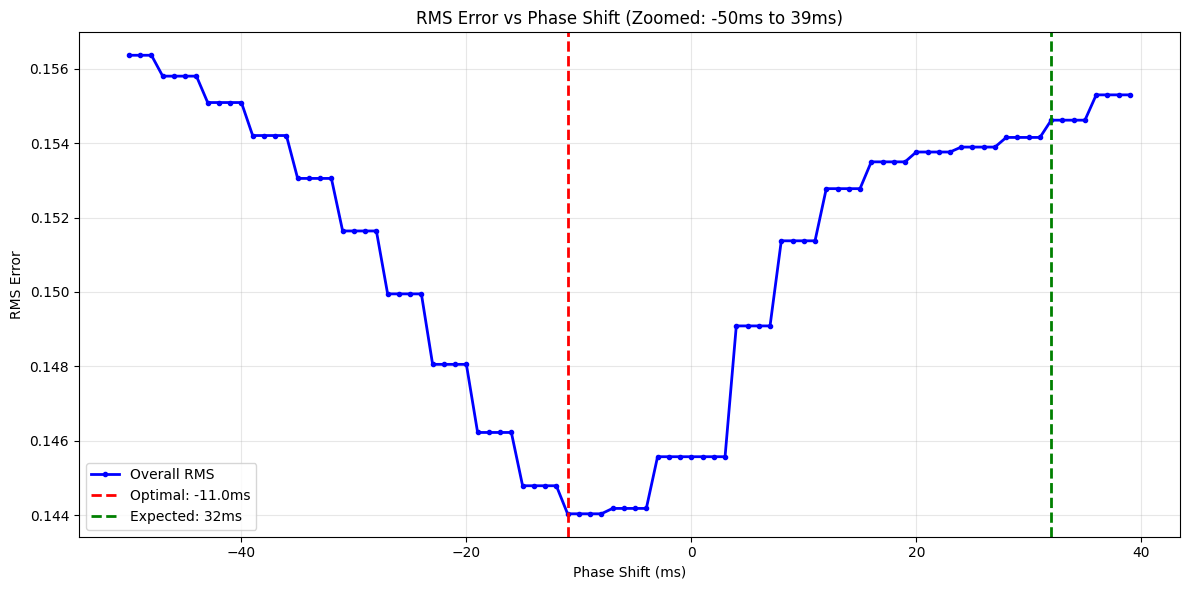

In [11]:
# Detailed zoom-in plot around optimal phase shift
zoom_range_ms = 50  # ±50ms around optimal
zoom_min = max(optimal_shift_ms - zoom_range_ms, min_shift_ms)
zoom_max = min(optimal_shift_ms + zoom_range_ms, max_shift_ms)
zoom_mask = (phase_shifts_ms >= zoom_min) & (phase_shifts_ms <= zoom_max)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(phase_shifts_ms[zoom_mask], overall_rms[zoom_mask], 'b-', linewidth=2, 
        label='Overall RMS', marker='o', markersize=3)
ax.axvline(x=optimal_shift_ms, color='r', linestyle='--', linewidth=2, 
           label=f'Optimal: {optimal_shift_ms:.1f}ms')
ax.axvline(x=expected_phase_shift_ms, color='g', linestyle='--', linewidth=2, 
           label=f'Expected: {expected_phase_shift_ms}ms')
ax.set_xlabel('Phase Shift (ms)')
ax.set_ylabel('RMS Error')
ax.set_title(f'RMS Error vs Phase Shift (Zoomed: {zoom_min:.0f}ms to {zoom_max:.0f}ms)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
